# Monte Carlo Option Pricing and Convergence Analysis

## Objective

This notebook implements Monte Carlo pricing for European call
and put options under the Black-Scholes framework.

The analysis focuses on:

- Simulating terminal stock prices using Geometric Brownian Motion.
- Estimating European option prices under the risk-neutral measure.
- Quantifying estimation uncertainty using standard errors and
  95% confidence intervals.
- Comparing Monte Carlo estimates with analytical Black-Scholes prices.
- Investigating the convergence rate using independent simulations
  and Root Mean Squared Error (RMSE).

## Model Assumptions

- The underlying follows Geometric Brownian Motion.
- Volatility and the risk-free rate are constant.
- The underlying pays no dividends.
- Options have European exercise.
- Pricing is performed under the risk-neutral measure.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Locate project root
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

assert (project_root / "src").is_dir(), "Project root not found"

In [5]:
# Model parameters
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

# Simulation parameters
n_simulations = 10000
seed = 42

In [6]:
# Create random number generator
rng = np.random.default_rng(seed)

# Generate standard normal random variables
Z = rng.standard_normal(n_simulations)

# Simulate terminal stock prices (drift + shock)
ST = S0 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z
)

print(f"Number of simulations: {len(ST)}")
print(f"Mean terminal stock price: {np.mean(ST):.4f}")
print(f"Minimum simulated price: {np.min(ST):.4f}")
print(f"Maximum simulated price: {np.max(ST):.4f}")

Number of simulations: 10000
Mean terminal stock price: 104.9382
Minimum simulated price: 42.8346
Maximum simulated price: 230.5194


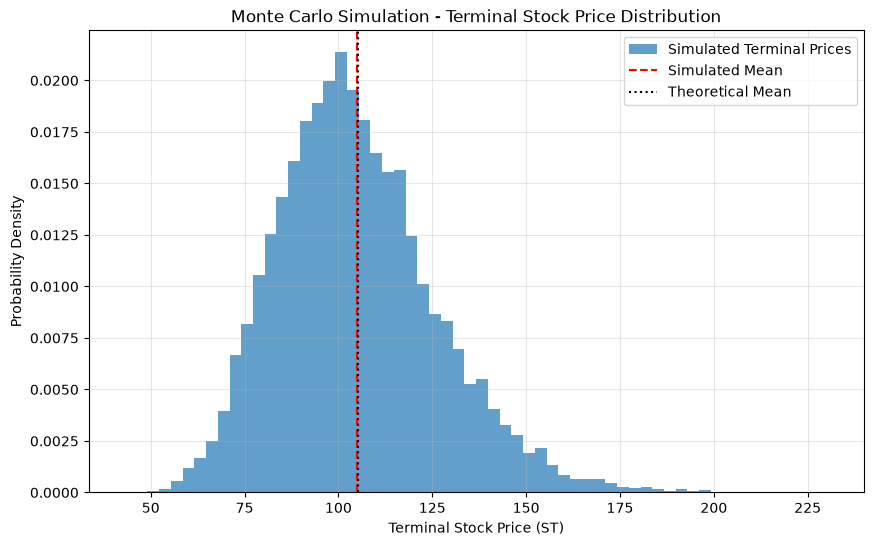

Theoretical Mean: 105.1271
Simulated Mean: 104.9382
Absolute Difference: 0.1889


In [7]:
# Theoretical expected terminal stock price
expected_ST = S0 * np.exp(r * T)

# Plot simulated terminal stock prices
plt.figure(figsize=(10, 6))

plt.hist(ST, bins=60, density=True, alpha=0.7,
         label="Simulated Terminal Prices")

plt.axvline(np.mean(ST), color="red", linestyle="--",
            label="Simulated Mean")

plt.axvline(expected_ST, color="black", linestyle=":",
            label="Theoretical Mean")

plt.xlabel("Terminal Stock Price (ST)")
plt.ylabel("Probability Density")
plt.title("Monte Carlo Simulation - Terminal Stock Price Distribution")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Theoretical Mean: {expected_ST:.4f}")
print(f"Simulated Mean: {np.mean(ST):.4f}")
print(f"Absolute Difference: {abs(np.mean(ST) - expected_ST):.4f}")

In [8]:
# Calculate option payoffs at maturity
call_payoffs = np.maximum(ST - K, 0)
put_payoffs = np.maximum(K - ST, 0)

# Discount factor
discount_factor = np.exp(-r * T)

# Monte Carlo option prices
call_mc = discount_factor * np.mean(call_payoffs)
put_mc = discount_factor * np.mean(put_payoffs)

print(f"Monte Carlo Call Price: {call_mc:.4f}")
print(f"Monte Carlo Put Price: {put_mc:.4f}")

Monte Carlo Call Price: 10.3452
Monte Carlo Put Price: 5.6478


In [9]:
# Discounted option payoffs
discounted_call = discount_factor * call_payoffs
discounted_put = discount_factor * put_payoffs

# Monte Carlo standard errors
call_se = np.std(discounted_call, ddof=1) / np.sqrt(n_simulations)
put_se = np.std(discounted_put, ddof=1) / np.sqrt(n_simulations)

# 95% confidence intervals
z = 1.96

call_ci = (call_mc - z * call_se, call_mc + z * call_se)
put_ci = (put_mc - z * put_se, put_mc + z * put_se)

# Results
print(f"Call MC Price: {call_mc:.4f}")
print(f"Call Standard Error: {call_se:.4f}")
print(f"Call 95% CI: [{call_ci[0]:.4f}, {call_ci[1]:.4f}]")

print()

print(f"Put MC Price: {put_mc:.4f}")
print(f"Put Standard Error: {put_se:.4f}")
print(f"Put 95% CI: [{put_ci[0]:.4f}, {put_ci[1]:.4f}]")


Call MC Price: 10.3452
Call Standard Error: 0.1477
Call 95% CI: [10.0558, 10.6346]

Put MC Price: 5.6478
Put Standard Error: 0.0879
Put 95% CI: [5.4756, 5.8201]


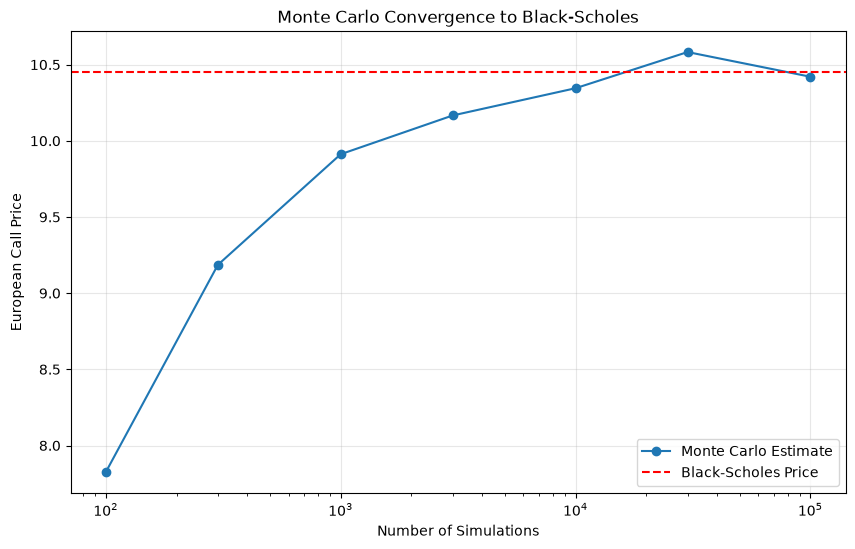

In [10]:
# Number of simulations to evaluate
N_values = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])

# Generate 100,000 random observations
rng = np.random.default_rng(42)
Z = rng.standard_normal(100000)

# Simulate terminal stock prices
ST = S0 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z
)

# Calculate discounted call payoffs
call_payoffs = np.exp(-r * T) * np.maximum(ST - K, 0)

# Monte Carlo estimates for different sample sizes
call_estimates = []

for N in N_values:
    estimate = np.mean(call_payoffs[:N])
    call_estimates.append(estimate)

# Black-Scholes benchmark
bs_call = 10.4505835722

# Plot convergence
plt.figure(figsize=(10, 6))

plt.plot(N_values, call_estimates, marker="o",
         label="Monte Carlo Estimate")

plt.axhline(bs_call, color="red", linestyle="--",
            label="Black-Scholes Price")

plt.xscale("log")
plt.xlabel("Number of Simulations")
plt.ylabel("European Call Price")
plt.title("Monte Carlo Convergence to Black-Scholes")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [11]:
# Sample sizes
N_values = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])

# Discounted call payoffs from the 100,000 simulated prices
discounted_payoffs = np.exp(-r * T) * np.maximum(ST - K, 0)

# Store results
mc_estimates = []
standard_errors = []

for N in N_values:

    # Select the first N discounted payoffs
    sample = discounted_payoffs[:N]

    # Monte Carlo price estimate
    estimate = np.mean(sample)

    # Standard error of the estimate
    se = np.std(sample, ddof=1) / np.sqrt(N)

    mc_estimates.append(estimate)
    standard_errors.append(se)

# Convert lists to NumPy arrays
mc_estimates = np.array(mc_estimates)
standard_errors = np.array(standard_errors)

# 95% confidence interval margins
ci_margins = 1.96 * standard_errors

# Display results
print("N         MC Price     Standard Error     95% CI")

for N, price, se, margin in zip(
    N_values, mc_estimates, standard_errors, ci_margins
):
    print(
        f"{N:<9} {price:<12.4f} {se:<18.4f} "
        f"[{price-margin:.4f}, {price+margin:.4f}]")

N         MC Price     Standard Error     95% CI
100       7.8258       1.0120             [5.8423, 9.8092]
300       9.1860       0.8223             [7.5743, 10.7977]
1000      9.9120       0.4483             [9.0332, 10.7907]
3000      10.1665      0.2645             [9.6481, 10.6849]
10000     10.3452      0.1477             [10.0558, 10.6346]
30000     10.5826      0.0860             [10.4141, 10.7511]
100000    10.4205      0.0468             [10.3289, 10.5122]


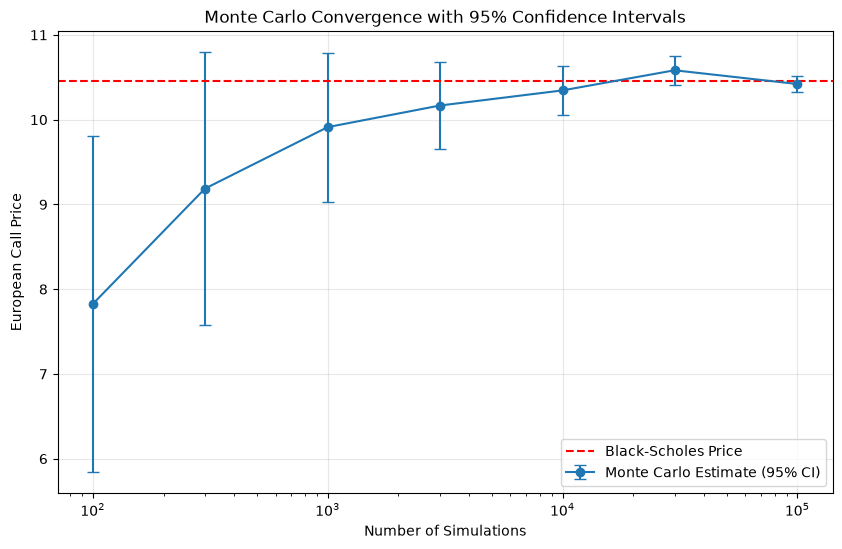

In [12]:
plt.figure(figsize=(10, 6))

# Monte Carlo estimates with 95% confidence intervals
plt.errorbar(
    N_values,
    mc_estimates,
    yerr=ci_margins,
    fmt="o-",
    capsize=4,
    label="Monte Carlo Estimate (95% CI)"
)

# Black-Scholes benchmark
plt.axhline(
    bs_call,
    color="red",
    linestyle="--",
    label="Black-Scholes Price"
)

plt.xscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("European Call Price")
plt.title("Monte Carlo Convergence with 95% Confidence Intervals")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# Independent Monte Carlo replications

N_values = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
n_replications = 100

rng = np.random.default_rng(123)

rmse_values = []

for N in N_values:

    estimates = []

    for rep in range(n_replications):

        # Generate independent random shocks
        Z = rng.standard_normal(N)

        # Simulate terminal stock prices
        ST_rep = S0 * np.exp(
            (r - 0.5 * sigma**2) * T
            + sigma * np.sqrt(T) * Z
        )

        # Discounted call payoff
        payoffs = np.exp(-r * T) * np.maximum(ST_rep - K, 0)

        # Monte Carlo price
        estimate = np.mean(payoffs)
        estimates.append(estimate)

    estimates = np.array(estimates)

    # Root Mean Squared Error
    rmse = np.sqrt(np.mean((estimates - bs_call)**2))

    rmse_values.append(rmse)

rmse_values = np.array(rmse_values)

for N, rmse in zip(N_values, rmse_values):
    print(f"N = {N:>6} | RMSE = {rmse:.6f}")

N =    100 | RMSE = 1.352933
N =    300 | RMSE = 0.867286
N =   1000 | RMSE = 0.464343
N =   3000 | RMSE = 0.299594
N =  10000 | RMSE = 0.157610
N =  30000 | RMSE = 0.074208
N = 100000 | RMSE = 0.047994


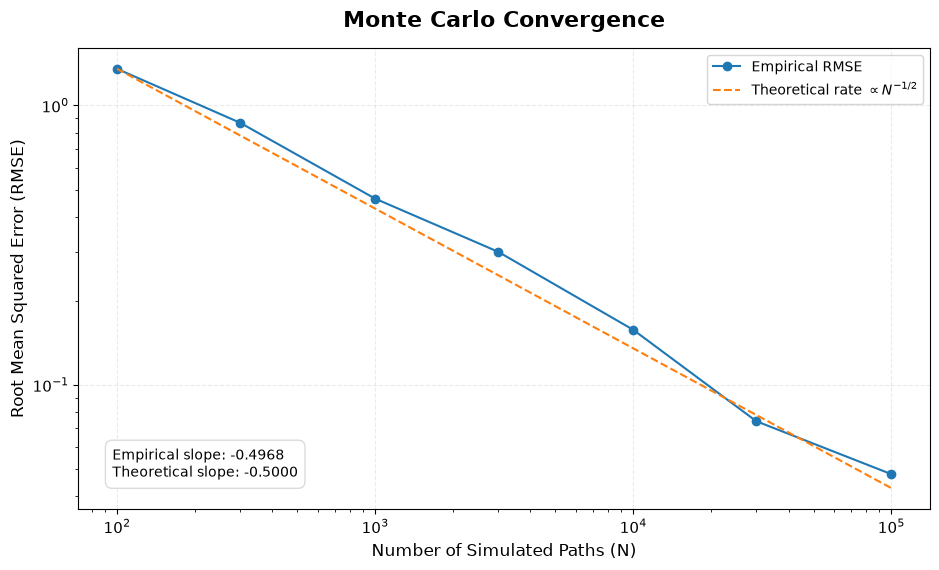

Estimated log-log slope: -0.4968
Theoretical slope: -0.5000


In [16]:
# Estimate empirical convergence rate
slope, intercept = np.polyfit(
    np.log(N_values),
    np.log(rmse_values),
    1
)

# Theoretical reference: N^(-1/2)
theoretical_rmse = rmse_values[0] * np.sqrt(N_values[0] / N_values)

# Plot
plt.figure(figsize=(10, 6))

plt.loglog(
    N_values, rmse_values,
    "o-", label="Empirical RMSE"
)

plt.loglog(
    N_values, theoretical_rmse,
    "--", label="Theoretical Rate: N^(-1/2)"
)

plt.xlabel("Number of Simulations")
plt.ylabel("Root Mean Squared Error")
plt.title("Monte Carlo Convergence Rate")


plt.legend()
plt.grid(True, which="both", alpha=0.3)

# Save figure
figures_path = project_root / "figures"
figures_path.mkdir(exist_ok=True)


# Final formatting - Monte Carlo convergence

ax = plt.gca()
fig = plt.gcf()

fig.set_size_inches(9.5, 5.8)

# Clean title and axis labels
ax.set_title(
    "Monte Carlo Convergence",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Number of Simulated Paths (N)",
    fontsize=12
)

ax.set_ylabel(
    "Root Mean Squared Error (RMSE)",
    fontsize=12
)

# Maintain logarithmic scales
ax.set_xscale("log")
ax.set_yscale("log")

# Simplify the grid
ax.grid(False, which="both")
ax.grid(
    True,
    which="major",
    linestyle="--",
    alpha=0.25,
    linewidth=0.8
)

# Improve legend labels
lines = ax.get_lines()

if len(lines) >= 2:
    lines[0].set_label("Empirical RMSE")
    lines[1].set_label(
        r"Theoretical rate $\propto N^{-1/2}$"
    )

ax.legend(
    loc="upper right",
    fontsize=10,
    frameon=True
)

# Display convergence estimates
annotation = (
    f"Empirical slope: {slope:.4f}\n"
    "Theoretical slope: -0.5000"
)

ax.text(
    0.04, 0.06,
    annotation,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.85",
        alpha=0.95
    )
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11
)

plt.tight_layout()


plt.savefig(
    figures_path / "monte_carlo_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Estimated log-log slope: {slope:.4f}")
print("Theoretical slope: -0.5000")

In [15]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.monte_carlo import monte_carlo_price

# Price a European Call
call_result = monte_carlo_price(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=100000,
    option_type="call",
    seed=42
)

print(f"MC Call Price: {call_result['price']:.4f}")
print(f"Standard Error: {call_result['standard_error']:.4f}")
print(
    f"95% CI: [{call_result['ci_lower']:.4f}, "
    f"{call_result['ci_upper']:.4f}]")

MC Call Price: 10.4205
Standard Error: 0.0468
95% CI: [10.3289, 10.5122]
